本 notebook 是 [M01.3 开发工具链](../notes/03-dev-toolchain.qmd) 的实例讲解。所有操作都在临时目录里进行，不会改动本仓库。内容：

1. Git 的对象模型：blob 的哈希就是“类型 + 长度 + 内容”的 SHA-1；
2. merge 与 rebase：同样的改动，rebase 产生了新的提交，旧提交仍在 reflog 里；
3. 一次真实的合并冲突与冲突标记；
4. `git bisect run`：在 64 个提交里自动定位引入回归的那一个；
5. Shell 脚本的 `set -euo pipefail`；
6. `logging`：级别、logger 层级与 handler；
7. 事后调试：从 traceback 里取回出错现场的局部变量；
8. pytest 与 ruff：参数化测试、浮点比较的陷阱、静态检查。

**运行方式**：在 VS Code 中打开本文件，选择仓库 `.venv` 的 Python 内核，从上到下运行。需要本机有 `git` 和 `bash`。改动代码后可用 `make nb M=01` 重新执行并保存输出。

In [1]:
import hashlib
import io
import logging
import math
import os
import re
import shutil
import subprocess
import sys
import tempfile
import textwrap
import traceback
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from semiai.plotting import BLUE, MUTED, ORANGE, use_style

use_style()

WORK = Path(tempfile.mkdtemp(prefix="m013-"))

# 隔离用户自己的 git 配置，并固定作者与时间：这样每次运行得到的提交哈希都相同。
GIT_ENV = {
    **{k: v for k, v in os.environ.items() if k not in ("FORCE_COLOR", "CLICOLOR_FORCE")},
    "NO_COLOR": "1",
    "GIT_CONFIG_GLOBAL": os.devnull,
    "GIT_CONFIG_NOSYSTEM": "1",
    "GIT_AUTHOR_NAME": "Learner",
    "GIT_AUTHOR_EMAIL": "learner@example.com",
    "GIT_COMMITTER_NAME": "Learner",
    "GIT_COMMITTER_EMAIL": "learner@example.com",
    "GIT_AUTHOR_DATE": "2026-01-01T00:00:00+00:00",
    "GIT_COMMITTER_DATE": "2026-01-01T00:00:00+00:00",
}


def clean(text: str) -> str:
    """把输出里的临时目录和 traceback 中的文件路径换成占位符，避免泄露本机路径。"""
    text = text.replace(str(WORK.resolve()), "<tmp>").replace(str(WORK), "<tmp>")
    return re.sub(r'File "[^"]*ipykernel[^"]*"', 'File "<notebook cell>"', text)


def sh(cmd: str | list[str], cwd: Path, check: bool = True, env: dict | None = None):
    """运行命令，返回 CompletedProcess；字符串命令交给 bash 执行。"""
    if isinstance(cmd, str):
        cmd = ["bash", "-c", cmd]
    return subprocess.run(cmd, cwd=cwd, env=env or GIT_ENV, capture_output=True,
                          text=True, check=check)


def git(repo: Path, *args: str, check: bool = True) -> str:
    return sh(["git", *args], repo, check=check).stdout.strip()


def new_repo(name: str) -> Path:
    repo = WORK / name
    repo.mkdir()
    git(repo, "-c", "init.defaultBranch=main", "init", "-q")
    return repo


def commit(repo: Path, files: dict[str, str], message: str, tick: int = 0) -> str:
    """写入文件并提交，返回提交哈希。tick 让每个提交的时间戳不同。"""
    for name, content in files.items():
        (repo / name).write_text(content)
    git(repo, "add", *files)
    env = {**GIT_ENV, "GIT_AUTHOR_DATE": f"2026-01-01T00:{tick // 60:02d}:{tick % 60:02d}+00:00"}
    env["GIT_COMMITTER_DATE"] = env["GIT_AUTHOR_DATE"]
    sh(["git", "commit", "-q", "-m", message], repo, env=env)
    return git(repo, "rev-parse", "HEAD")


print("git:", git(WORK, "--version"))

git: git version 2.54.0 (Apple Git-157)


## 1. Git 的对象模型：内容寻址

Git 仓库本质上是一个键值数据库：键是内容的哈希，值是压缩后的对象。对象只有几种：**blob**（文件内容）、**tree**（目录：文件名 → blob/tree 的哈希）、**commit**（指向一个 tree、若干父提交，加作者和说明）。下面验证 blob 的哈希就是对 `"blob <字节数>\0" + 内容` 做 SHA-1。

In [2]:
repo = new_repo("objects")
content = "E_cut = 520 eV\nk_mesh = 6 6 6\n"
c1 = commit(repo, {"INCAR.txt": content}, "add input parameters")

blob_git = git(repo, "rev-parse", "HEAD:INCAR.txt")
data = content.encode()
blob_py = hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()
print("git 记录的 blob 哈希 :", blob_git)
print("hashlib 手算        :", blob_py)
print("二者相同             :", blob_git == blob_py)
print()
print("commit 对象的原文 (git cat-file -p HEAD):")
print(git(repo, "cat-file", "-p", "HEAD"))
print()
print("tree 对象 (git cat-file -p HEAD^{tree}):")
print(git(repo, "cat-file", "-p", "HEAD^{tree}"))

git 记录的 blob 哈希 : f507b4999ee8687a36319c175ff3c0132ecfcd52
hashlib 手算        : f507b4999ee8687a36319c175ff3c0132ecfcd52
二者相同             : True

commit 对象的原文 (git cat-file -p HEAD):
tree 0fe74ce564002d3cbcdb666efcaf37e70b4bfb06
author Learner <learner@example.com> 1767225600 +0000
committer Learner <learner@example.com> 1767225600 +0000

add input parameters

tree 对象 (git cat-file -p HEAD^{tree}):
100644 blob f507b4999ee8687a36319c175ff3c0132ecfcd52	INCAR.txt


读法：commit 对象只是一小段文本，里面写着 tree 的哈希、作者、时间和说明；它自己的哈希又是对这段文本做 SHA-1。所以**提交哈希取决于内容、父提交、作者和时间**，改动其中任何一项都会得到一个新提交。下一节的 rebase 就是这条性质的直接后果。

这个 notebook 固定了作者和时间，所以你重新运行得到的哈希与这里显示的一致。

## 2. merge 与 rebase

构造一个分叉：`main` 上有提交 A、C，`feature` 从 A 分出、有提交 B。分别用 merge 和 rebase 把两条线合起来。

In [3]:
repo = new_repo("history")
a = commit(repo, {"relax.py": "steps = 100\n"}, "A: baseline relaxation", tick=1)
git(repo, "switch", "-q", "-c", "feature")
b = commit(repo, {"analysis.py": "plot_rdf()\n"}, "B: add RDF analysis", tick=2)
git(repo, "switch", "-q", "main")
c = commit(repo, {"relax.py": "steps = 200\n"}, "C: longer relaxation", tick=3)

# merge：在 main 的副本上合并 feature
git(repo, "switch", "-q", "-c", "merged", "main")
git(repo, "merge", "-q", "--no-ff", "-m", "M: merge feature", "feature")
print("merge 之后的历史：")
print(git(repo, "log", "--graph", "--oneline", "--format=%h %s"))

# rebase：把 feature 的副本搬到 main 之上
git(repo, "switch", "-q", "-c", "rebased", "feature")
git(repo, "rebase", "-q", "main")
b_new = git(repo, "rev-parse", "HEAD")
print("\nrebase 之后的历史：")
print(git(repo, "log", "--graph", "--oneline", "--format=%h %s"))

print(f"\n原来的 B : {b[:7]}   rebase 后的 B': {b_new[:7]}   相同吗？{b == b_new}")
diff_old = git(repo, "diff", f"{b}^", b)
diff_new = git(repo, "diff", f"{b_new}^", b_new)
print("两者引入的改动 (diff) 相同吗？", diff_old == diff_new)
print("\nreflog 里仍能找到原来的 B：")
print(git(repo, "reflog", "--format=%h %gs", "-n", "4"))

merge 之后的历史：
*   12ab26d M: merge feature
|\  
| * 3131ba0 B: add RDF analysis
* | 92521ec C: longer relaxation
|/  
* 092e5c4 A: baseline relaxation

rebase 之后的历史：
* fd158f8 B: add RDF analysis
* 92521ec C: longer relaxation
* 092e5c4 A: baseline relaxation

原来的 B : 3131ba0   rebase 后的 B': fd158f8   相同吗？False
两者引入的改动 (diff) 相同吗？ True

reflog 里仍能找到原来的 B：
fd158f8 rebase (finish): returning to refs/heads/rebased
fd158f8 rebase (pick): B: add RDF analysis
92521ec rebase (start): checkout main
3131ba0 checkout: moving from merged to rebased


读法：

- merge 保留了真实的分叉历史，多出一个有两个父提交的合并提交 M，原有提交的哈希都不变。
- rebase 把 B 的**改动**重新应用在 C 之上，生成了一个新提交 B'：diff 完全相同，但父提交变了，哈希随之改变。所谓“rebase 改写历史”就是这个意思。如果别人已经基于旧的 B 工作，你推送 B' 之后他们的历史就和你的对不上了，所以**不要 rebase 已经共享出去的提交**。
- 旧的 B 并没有消失，reflog 还记着它。误操作之后用 `git reflog` 找回哈希，再 `git branch rescue <哈希>` 即可恢复。reflog 只存在于本地，且有期限：默认 90 天后过期，像旧 B 这样已经不能从分支末端到达的条目只保留 30 天（`gc.reflogExpire`、`gc.reflogExpireUnreachable`）。

## 3. 合并冲突

两条分支修改了同一行，Git 无法自动决定保留哪个，就会停下来，把两种版本都写进文件。

In [4]:
repo = new_repo("conflict")
commit(repo, {"params.toml": "temperature = 300\nsteps = 1000\n"}, "base", tick=1)
git(repo, "switch", "-q", "-c", "hot")
commit(repo, {"params.toml": "temperature = 900\nsteps = 1000\n"}, "melt at 900 K", tick=2)
git(repo, "switch", "-q", "main")
commit(repo, {"params.toml": "temperature = 600\nsteps = 1000\n"}, "anneal at 600 K", tick=3)

result = sh(["git", "merge", "hot"], repo, check=False)
print("git merge 的返回码:", result.returncode)
print(result.stdout.strip())
print("\n冲突文件的内容：")
print((repo / "params.toml").read_text())
print("git status --short:", git(repo, "status", "--short"))

# 解决：人工决定保留哪个值，然后 add + commit
(repo / "params.toml").write_text("temperature = 900\nsteps = 1000\n")
git(repo, "add", "params.toml")
git(repo, "commit", "-q", "--no-edit")
print("解决后的最新提交:", git(repo, "log", "-1", "--format=%s"))

git merge 的返回码: 1
Auto-merging params.toml
CONFLICT (content): Merge conflict in params.toml
Automatic merge failed; fix conflicts and then commit the result.

冲突文件的内容：
<<<<<<< HEAD
temperature = 600
temperature = 900
>>>>>>> hot
steps = 1000

git status --short: UU params.toml
解决后的最新提交: Merge branch 'hot'


读法：`<<<<<<< HEAD` 到 `=======` 之间是当前分支（main）的版本，`=======` 到 `>>>>>>> hot` 之间是被合并分支的版本。冲突只发生在同一区域被双方修改时，`steps` 那一行没有冲突。解决冲突就是把文件改成你想要的样子、删掉标记、`git add`，再提交。改动越小、合并越频繁，冲突越少。

## 4. `git bisect run`：二分查找引入回归的提交

造一段 64 个提交的历史。每个提交改一点“能量函数”，第 41 个提交悄悄引入了一个符号错误。写一个测试脚本：能量正确则退出码为 0，错误则为 1。`git bisect run` 会自动二分。

In [5]:
repo = new_repo("bisect")
N_COMMITS, BAD = 64, 41
hashes = []
for i in range(1, N_COMMITS + 1):
    sign = "-" if i >= BAD else "+"
    code = f"# revision {i}\ndef energy(x):\n    return {sign}0.5 * x * x\n"
    hashes.append(commit(repo, {"model.py": code}, f"rev {i}", tick=i))

def bisect(python_flags: str) -> tuple[str, int]:
    """用测试脚本自动二分，返回（找到的第一个坏提交的说明, 测试次数）。"""
    shutil.rmtree(repo / "__pycache__", ignore_errors=True)
    script = WORK / "check_energy.sh"  # 退出码 0 = good，1 = bad
    script.write_text(
        "#!/usr/bin/env bash\n"
        f'"{sys.executable}" {python_flags} -c '
        '"import model, sys; sys.exit(0 if model.energy(2.0) > 0 else 1)"\n'
    )
    git(repo, "bisect", "start", hashes[-1], hashes[0])  # 先 bad 后 good
    out = sh(["git", "bisect", "run", "bash", str(script)], repo).stdout
    git(repo, "bisect", "reset")
    first_bad = re.search(r"([0-9a-f]{40}) is the first bad commit", out).group(1)
    n_tests = len(re.findall(r"^running", out, flags=re.M))
    return git(repo, "log", "-1", "--format=%s", first_bad), n_tests


for flags, label in (("-B", "python -B（不用 .pyc 缓存）"), ("", "python（默认，允许 .pyc 缓存）")):
    found, n_tests = bisect(flags)
    verdict = "正确" if found == f"rev {BAD}" else "错误"
    print(f"{label:<28} 找到: {found:<7} 测试次数: {n_tests}  → {verdict}")
print(f"真实答案: rev {BAD}；理论测试次数 ceil(log2({N_COMMITS - 1})) = "
      f"{math.ceil(math.log2(N_COMMITS - 1))}")

python -B（不用 .pyc 缓存）        找到: rev 41  测试次数: 6  → 正确
python（默认，允许 .pyc 缓存）        找到: rev 64  测试次数: 6  → 错误
真实答案: rev 41；理论测试次数 ceil(log2(63)) = 6


读法：好坏之间有 63 个“可疑区间”，二分只需要 6 次测试，与讲义的[二分步数公式](../notes/03-dev-toolchain.qmd#eq-bisect)一致；逐个检查最多需要 62 次。前提是测试能自动、可靠地给出 good/bad：bisect 的效率完全建立在“有一个可信的回归测试”之上。退出码 125 可以告诉 bisect “这个提交无法测试，跳过”。

第二行是起草这个 notebook 时真实踩到的坑：同样的脚本、同样的历史，只是允许了字节码缓存，bisect 就可能给出错误答案。是否出错取决于时序，你重新运行时可能得到正确结果，也可能得到另一个错误结果。Python 把 `model.py` 编译成 `__pycache__/*.pyc`，下次导入时只比较源文件的**修改时间（精确到秒）和大小**来判断缓存是否过期。bisect 在一秒之内反复切换版本，而各版本的 `model.py` 大小又常常相同，于是测试导入的是旧缓存，结果与当前检出的代码无关。**测试本身不可信时，自动化只会更快地给出错误答案。** 用 `-B` 或环境变量 `PYTHONDONTWRITEBYTECODE=1` 可以避开它；更一般的做法是让测试在干净的环境里运行。

下面把二分的过程画出来：每一步可疑区间减半。

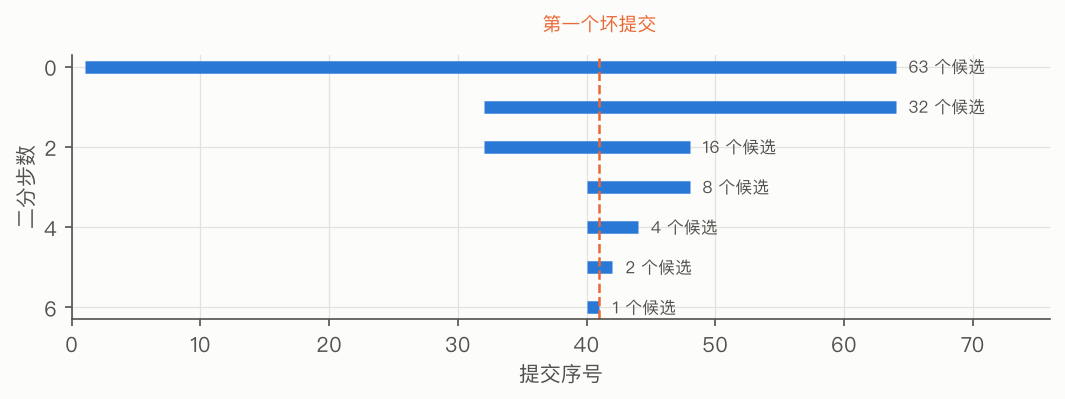

In [6]:
lo, hi = 1, N_COMMITS  # rev 1 good, rev 64 bad
steps = [(lo, hi)]
while hi - lo > 1:
    mid = (lo + hi) // 2
    if mid >= BAD:
        hi = mid
    else:
        lo = mid
    steps.append((lo, hi))

fig, ax = plt.subplots(figsize=(7.2, 2.8))
for k, (left, right) in enumerate(steps):
    ax.plot([left, right], [k, k], color=BLUE, lw=6, solid_capstyle="butt")
    ax.text(right + 1, k, f"{right - left} 个候选", va="center", fontsize=8, color=MUTED)
ax.axvline(BAD, color=ORANGE, ls="--", lw=1.2)
ax.text(BAD, -0.9, "第一个坏提交", color=ORANGE, ha="center", fontsize=9)
ax.set(xlim=(0, N_COMMITS + 12), xlabel="提交序号", ylabel="二分步数")
ax.invert_yaxis()
fig.tight_layout()
plt.show()

## 5. Shell 脚本的 `set -euo pipefail`

Bash 默认**出错也继续执行**：某一步失败了，后面的步骤照样跑，最后脚本可能还返回 0。对一个“生成输入 → 提交计算 → 后处理”的流水线，这意味着在不完整的数据上跑后处理而不自知。

In [7]:
body = textwrap.dedent("""\
    cp missing_POSCAR POSCAR          # 文件不存在，这一步失败
    echo "submitting job with $NCORES cores"
    grep TOTEN OUTCAR | tail -n 1     # OUTCAR 也不存在
    echo "post-processing done"
""")
for header in ("", "set -euo pipefail\n"):
    script = "#!/usr/bin/env bash\n" + header + body
    r = sh(["bash", "-c", script], WORK, check=False)
    print(f"=== 头部: {header.strip() or '(无)'} ===")
    print("stdout:", r.stdout.strip().replace("\n", " | ") or "(空)")
    print("stderr:", clean(r.stderr.strip()).replace("\n", " | "))
    print("返回码:", r.returncode, "\n")

r = sh(["bash", "-c", "false | true; echo \"无 pipefail: $?\"; "
        "set -o pipefail; false | true; echo \"有 pipefail: $?\""], WORK)
print(r.stdout.strip())
for header, label in (("", "无 -u"), ("set -u; ", "有 -u")):
    r = sh(["bash", "-c", header + 'echo "cores=[$NCORES]"'], WORK, check=False)
    print(f"{label}: {(r.stdout or r.stderr).strip()}  (返回码 {r.returncode})")

=== 头部: (无) ===
stdout: submitting job with  cores | post-processing done
stderr: cp: missing_POSCAR: No such file or directory | grep: OUTCAR: No such file or directory
返回码: 0 

=== 头部: set -euo pipefail ===
stdout: (空)
stderr: cp: missing_POSCAR: No such file or directory
返回码: 1 

无 pipefail: 0
有 pipefail: 1
无 -u: cores=[]  (返回码 0)
有 -u: bash: NCORES: unbound variable  (返回码 127)


读法：没有保护时，`cp` 失败后脚本照常打印“submitting”和“post-processing done”，最终返回 0，调用者以为一切正常。加上 `set -e` 后第一处失败就退出，返回码非零。注意第一段输出里的 “with  cores”：`$NCORES` 没有定义，被悄悄展开成了空字符串；`-u` 让这种情况直接报错（最后两行）。`pipefail` 让管道中任何一段失败都算失败，默认情况下管道的返回码只看最后一段。

## 6. `logging`：比 `print` 多了什么

`logging` 的三个概念：**logger** 按点号组成层级（`semiai.md.thermostat` 是 `semiai.md` 的子级），**level** 决定哪些消息被记录，**handler** 决定消息去哪里（终端、文件）、用什么格式。下面把两个 handler 接在父级 logger 上：终端只看 WARNING 及以上，文件记录全部。

In [8]:
console, logfile = io.StringIO(), io.StringIO()  # 用内存代替终端和文件

parent = logging.getLogger("demo")
parent.setLevel(logging.DEBUG)
parent.handlers.clear()
fmt = logging.Formatter("%(levelname)-7s %(name)s: %(message)s")
for stream, level in ((console, logging.WARNING), (logfile, logging.DEBUG)):
    h = logging.StreamHandler(stream)
    h.setLevel(level)
    h.setFormatter(fmt)
    parent.addHandler(h)
parent.propagate = False

log = logging.getLogger("demo.md.thermostat")  # 子级 logger，消息向上传给 demo 的 handler
log.debug("Nose-Hoover chain length = %d", 3)
log.info("step %d  T = %.1f K", 1000, 301.7)
log.warning("temperature drift %.1f K over 1 ps", 12.4)
try:
    c_v = 1.0 / 0.0  # 模拟一个出错的计算
except ZeroDivisionError:
    log.exception("failed to compute heat capacity")

print("---- 终端 handler（WARNING 及以上）----")
print(clean(console.getvalue()))
print("---- 文件 handler（DEBUG 及以上）----")
print(clean(logfile.getvalue()))

---- 终端 handler（WARNING 及以上）----
WARNING demo.md.thermostat: temperature drift 12.4 K over 1 ps
ERROR   demo.md.thermostat: failed to compute heat capacity
Traceback (most recent call last):
  File "<notebook cell>", line 19, in <module>
    c_v = 1.0 / 0.0  # 模拟一个出错的计算
          ~~~~^~~~~
ZeroDivisionError: float division by zero

---- 文件 handler（DEBUG 及以上）----
DEBUG   demo.md.thermostat: Nose-Hoover chain length = 3
INFO    demo.md.thermostat: step 1000  T = 301.7 K
WARNING demo.md.thermostat: temperature drift 12.4 K over 1 ps
ERROR   demo.md.thermostat: failed to compute heat capacity
Traceback (most recent call last):
  File "<notebook cell>", line 19, in <module>
    c_v = 1.0 / 0.0  # 模拟一个出错的计算
          ~~~~^~~~~
ZeroDivisionError: float division by zero



读法：同一条 `log.xxx()` 调用按级别分流，终端只有 2 条，日志文件有 4 条且带完整 traceback（`log.exception` 自动附上）。库代码里只写 `logging.getLogger(__name__)` 和 `log.info(...)`，不配置 handler；配置只在程序入口做一次。这样调用你代码的脚本能决定要看多详细的信息，而 `print` 做不到这一点。另一个好处：`%` 风格的参数只有在消息真正被记录时才格式化。

## 7. 事后调试：取回出错现场

长时间运行的计算在第 N 步崩溃时，最有价值的信息是**崩溃那一刻的局部变量**。`pdb.post_mortem()` 做的就是进入异常发生时的栈帧。notebook 里不方便交互，这里用它背后的机制——traceback 对象——把现场取出来。

In [9]:
def lj_energy(r: np.ndarray, eps: float = 1.0, sigma: float = 1.0) -> np.ndarray:
    sr6 = (sigma / r) ** 6
    return 4 * eps * (sr6**2 - sr6)


def total_energy(positions: np.ndarray) -> float:
    total = 0.0
    for i in range(len(positions)):
        for j in range(i + 1, len(positions)):
            r = np.linalg.norm(positions[i] - positions[j])
            if r == 0:
                raise ValueError(f"atoms {i} and {j} overlap")
            total += lj_energy(r)
    return total


pos = np.array([[0.0, 0, 0], [1.1, 0, 0], [0, 1.2, 0], [1.1, 0, 0]])  # 第 4 个原子与第 2 个重合
try:
    total_energy(pos)
except ValueError:
    exc_type, exc, tb = sys.exc_info()
    frames = traceback.extract_tb(tb)
    print("异常:", exc_type.__name__, "-", exc)
    print("调用链:", " → ".join(f.name for f in frames))
    while tb.tb_next is not None:  # 走到最内层的栈帧，也就是 pdb.post_mortem() 停下的地方
        tb = tb.tb_next
    local = tb.tb_frame.f_locals
    print("出错时的局部变量: i =", local["i"], " j =", local["j"],
          " 已累计能量 total =", round(local["total"], 4))

异常: ValueError - atoms 1 and 3 overlap
调用链: <module> → total_energy
出错时的局部变量: i = 1  j = 3  已累计能量 total = -3.0611


读法：不加任何 print，就拿到了出错时的 `i`、`j` 和已经累计的能量。实际调试时有三种进入方式：在代码里写 `breakpoint()`；对崩溃的脚本用 `python -m pdb script.py`，出错后自动停在现场；在 IPython / Jupyter 里异常之后输入 `%debug`。进入后常用的命令是 `p 表达式`、`up`/`down`（在栈帧间移动）、`ll`（显示当前函数源码）。VS Code 调试器提供同样的能力，外加图形化的变量面板和条件断点。

## 8. pytest 与 ruff

在临时目录写一个小模块和它的测试，用 pytest 运行。其中一个测试故意用 `==` 比较浮点数。

In [10]:
proj = WORK / "proj"
proj.mkdir()
(proj / "units.py").write_text(textwrap.dedent("""\
    HARTREE_TO_EV = 27.211386245988


    def hartree_to_ev(e):
        return e * HARTREE_TO_EV


    def mean_energy(energies):
        return sum(energies) / len(energies)
"""))
(proj / "test_units.py").write_text(textwrap.dedent("""\
    import pytest

    from units import hartree_to_ev, mean_energy


    @pytest.mark.parametrize("e_ha, e_ev", [(0.0, 0.0), (1.0, 27.211386245988), (-0.5, -13.605693)])
    def test_hartree_to_ev(e_ha, e_ev):
        assert hartree_to_ev(e_ha) == pytest.approx(e_ev, abs=1e-6)


    def test_mean_exact_equality():
        assert mean_energy([0.1, 0.2]) * 2 == 0.3          # 浮点陷阱


    def test_mean_with_tolerance():
        assert mean_energy([0.1, 0.2]) * 2 == pytest.approx(0.3)
"""))
r = sh([sys.executable, "-B", "-m", "pytest", "-q", "-p", "no:cacheprovider", "--no-header",
        "-rf", "--color=no"], proj, check=False)
lines = [ln for ln in r.stdout.splitlines() if ln.strip()]
print("\n".join(clean(ln) for ln in lines if re.search(r"passed|failed|FAILED|assert|where", ln)))
print("pytest 返回码:", r.returncode)

>       assert mean_energy([0.1, 0.2]) * 2 == 0.3          # 浮点陷阱
E       assert (0.15000000000000002 * 2) == 0.3
E        +  where 0.15000000000000002 = mean_energy([0.1, 0.2])
FAILED test_units.py::test_mean_exact_equality - assert (0.15000000000000002 ...
1 failed, 4 passed in 0.01s
pytest 返回码: 1


读法：参数化把 3 组输入展开成 3 个独立测试，每个都单独报告。`0.1 + 0.2` 在二进制浮点下不等于 `0.3`（差约 $5.6\times10^{-17}$），所以精确比较失败；`pytest.approx` 默认用 $10^{-6}$ 的相对容差。数值代码的测试几乎都应该带容差，而容差应该有依据（见 [代码规范](../../../docs/coding-standards.md) 第 7 节）。

最后用 ruff 检查一段有问题的代码。

In [11]:
(proj / "bad.py").write_text(textwrap.dedent("""\
    import os, sys
    import numpy as np


    def read_energies(path, cache=[]):
        try:
            data = np.loadtxt(path)
        except:
            return None
        if data == None:
            return cache
        return data
"""))
r = sh([sys.executable, "-m", "ruff", "check", "--no-cache", "--select", "E,F,B",
        "--output-format", "concise", "bad.py"], proj, check=False)
print(clean(r.stdout.strip()))

bad.py:1:1: E401 [*] Multiple imports on one line
bad.py:1:8: F401 [*] `os` imported but unused
bad.py:1:12: F401 [*] `sys` imported but unused
bad.py:5:31: B006 Do not use mutable data structures for argument defaults
bad.py:8:5: E722 Do not use bare `except`
bad.py:10:16: E711 Comparison to `None` should be `cond is None`
Found 6 errors.
[*] 3 fixable with `--fix` (2 unsafe fixes available with `--fix --unsafe-fixes`).


读法：ruff 在不运行代码的情况下找出了未使用的导入、裸 `except`（会吞掉 `KeyboardInterrupt` 等一切异常）、可变默认参数（`cache=[]` 在多次调用间共享，是经典 bug），以及 `== None`（对 NumPy 数组还会得到逐元素比较的结果）。本仓库在 `make check` 和 pre-commit 钩子里都运行 ruff，所以这类问题在提交前就被拦下。

本仓库的工具链把这些环节串了起来：`uv` 按 `uv.lock` 精确重建环境，`ruff` 做静态检查，`pytest` 跑测试，pre-commit 在每次 `git commit` 前自动运行前两者，CI 在推送后再跑一遍。见 [Makefile](../../../Makefile)、[.pre-commit-config.yaml](../../../.pre-commit-config.yaml) 和 [pyproject.toml](../../../pyproject.toml)。

In [12]:
shutil.rmtree(WORK)  # 清理临时目录
print("临时目录已删除:", not WORK.exists())

临时目录已删除: True


## 小结

- Git 对象是内容寻址的：提交哈希由内容、父提交、作者和时间共同决定，所以 rebase 必然产生新提交；旧提交可以从 reflog 找回。
- 冲突只出现在双方改了同一区域时；解决冲突就是编辑文件、`git add`、提交。
- `git bisect run` 用约 $\lceil\log_2 N\rceil$ 次自动测试定位回归，前提是有可靠的测试脚本。
- Shell 脚本默认出错继续执行，`set -euo pipefail` 让失败尽早、明确地暴露。
- `logging` 把“记录什么”和“输出到哪里”分开；`log.exception` 自动附带 traceback。
- 事后调试能直接取回崩溃现场的局部变量：`breakpoint()`、`python -m pdb`、`%debug`。
- 浮点比较要带容差；ruff 在运行前就能发现一类常见 bug。

可以尝试：把第 4 节的 `BAD` 改成 2 或 64，看 bisect 的测试次数是否变化；在第 2 节 rebase 之前先把 `feature` 推到另一个“远程”仓库（`git init --bare`），体会改写已共享历史带来的麻烦；给第 8 节的 `bad.py` 运行 `ruff check --fix`，看哪些问题能自动修复。